# Bài tập Thực hành 4: Phân lập Giọng nói (Voice Activity Detection - VAD) dựa trên Mô hình Thống kê GMM (Gaussian Mixture Model)

Trong bài tập này, các bạn sẽ thực hành xây dựng và đánh giá quy trình **Phân lập Giọng nói (Voice Activity Detection - VAD)** - một kỹ thuật tiền xử lý cốt lõi nhằm xác định các phân đoạn có chứa giọng nói (Speech) và không chứa giọng nói (Silence / Background Noise) trong tín hiệu âm thanh:

1. **Tải & Nạp Dữ liệu Âm thanh**: Tải tự động bộ dữ liệu `Speech Commands Dataset` từ internet, giải nén và tạo luồng âm thanh chứa các đoạn phát âm xen kẽ khoảng lặng/nhiễu nền cùng mảng nhãn chuẩn (**Ground Truth Labels**).
2. **Trích xuất Đặc trưng Băng tần (Sub-band Energy Extraction)**: Chia tín hiệu thành các khung 20ms và trích xuất vector đặc trưng Năng lượng Log trên 6 dải tần số.
3. **Huấn luyện Mô hình GMM với `sklearn.mixture`**: Sử dụng thư viện `sklearn.mixture.GaussianMixture` để huấn luyện 2 mô hình GMM đại diện cho lớp Nhiễu (`gmm_noise`) và lớp Giọng nói (`gmm_speech`), tính Tỉ số Likelihood Logarithm (**Log-Likelihood Ratio - LLR**) để quyết định VAD.
4. **Đánh giá Mô hình bằng `sklearn.metrics`**: Sử dụng các hàm chuẩn của `scikit-learn` để tính toán **Classification Report**, **Confusion Matrix**, **ROC Curve** và **AUC Score**.
5. **Trực quan hóa Đánh giá Chi tiết**: Trực quan hóa dạng sóng (Waveform), phân đoạn VAD, ma trận nhầm lẫn và đường cong ROC.
6. **Câu hỏi thảo luận**: Phân tích cơ chế hoạt động, lựa chọn số lượng component và tinh chỉnh ngưỡng quyết định.

## 1. Import các thư viện cần thiết
Chạy cell dưới đây để nạp các thư viện nạp file/tải dữ liệu (`urllib`, `zipfile`, `glob`), xử lý âm thanh (`librosa`), xử lý mảng số (`numpy`), mô hình GMM (`sklearn.mixture`), đánh giá mô hình (`sklearn.metrics`) và trực quan hóa (`matplotlib`, `seaborn`).

In [1]:
# Chạy lệnh này trong terminal nếu chưa cài đặt thư viện:
# pip install librosa numpy matplotlib scikit-learn seaborn scipy

import os
import glob
import zipfile
import urllib.request
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd
from sklearn.mixture import GaussianMixture
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

# Cấu hình seed ngẫu nhiên để kết quả có tính tái lập (reproducible)
SEED = 42
np.random.seed(SEED)
print(f"Librosa version: {librosa.__version__}")


Librosa version: 1.0.0


## 2. Tải Dữ liệu Âm thanh & Tạo Tín hiệu kèm Nhãn chuẩn (Ground Truth)
Chúng ta tải bộ dữ liệu **Mini Speech Commands Dataset** từ lưu trữ TensorFlow trực tuyến.
Để đánh giá chính xác mô hình VAD bằng các chỉ số đánh giá (`sklearn.metrics`), chúng ta tạo ra một tín hiệu âm thanh thử nghiệm dài khoảng $6\text{ giây}$ và danh sách **Nhãn chuẩn theo thời gian (Ground Truth Intervals)**:
- Trong các khoảng thời gian chứa file âm thanh giọng nói: `Label = 1` (Speech).
- Trong các khoảng thời gian chèn nhiễu nền/khoảng lặng: `Label = 0` (Noise/Silence).

In [2]:
# TODO 1: Tải bộ dữ liệu, ghép nối chuỗi âm thanh VAD và tạo danh sách phân đoạn nhãn chuẩn (speech_intervals)
# Yêu cầu:
# 1. Tải 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip' nếu chưa có.
# 2. Giải nén vào thư mục 'dataset_speech_commands'.
# 3. Chọn 4 file .wav lệnh giọng nói ngẫu nhiên, đọc bằng librosa.load(..., sr=16000, mono=True).
# 4. Tạo tín hiệu y bằng cách nối: [Nhiễu 0.5s] + [Speech 1] + [Nhiễu 0.4s] + [Speech 2] + [Nhiễu 0.4s] + [Speech 3] + [Nhiễu 0.4s] + [Speech 4] + [Nhiễu 0.4s].
#    (Nhiễu nền được chèn bằng np.random.normal(0, 0.0008, int(sr*duration)))
# 5. Lưu danh sách các khoảng thời gian chứa giọng nói thực tế: speech_intervals = [(start_sec, end_sec), ...].
#
# Đầu ra:
# - y: mảng numpy 1D chứa tín hiệu âm thanh (float32).
# - sr: 16000.
# - speech_intervals: danh sách các tuple [(start1, end1), (start2, end2), ...]

url = 'https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
zip_path = 'mini_speech_commands.zip'
extract_dir = 'dataset_speech_commands'

if not os.path.exists(zip_path) and not os.path.exists(extract_dir):
    print("Dang tai bo du lieu Speech Commands tu internet...")
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_dir):
    print("Dang giai nen bo du lieu...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

sr = 16000
wav_files = glob.glob(os.path.join(extract_dir, "*", "*.wav"))
if not wav_files:
    wav_files = glob.glob(os.path.join(extract_dir, "**", "*.wav"), recursive=True)

rng = np.random.RandomState(SEED)
selected_files = rng.choice(wav_files, 4, replace=False)

speeches = []
for f in selected_files:
    audio, _ = librosa.load(f, sr=sr, mono=True)
    speeches.append(audio)

noise_init = rng.normal(0, 0.0008, int(sr * 0.5)).astype(np.float32)
noise_gap = rng.normal(0, 0.0008, int(sr * 0.4)).astype(np.float32)

y_parts = [noise_init]
speech_intervals = []
curr_time = 0.5

for sp in speeches:
    sp_duration = len(sp) / sr
    start_t = curr_time
    end_t = curr_time + sp_duration
    speech_intervals.append((start_t, end_t))
    y_parts.append(sp.astype(np.float32))
    curr_time = end_t
    y_parts.append(noise_gap.astype(np.float32))
    curr_time += 0.4

y = np.concatenate(y_parts).astype(np.float32)

if y is not None:
    print(f"Tan so lay mau: {sr} Hz, Thoi luong: {len(y)/sr:.2f}s")
    print(f"Cac phan doan Giong noi chuan (Ground Truth Intervals): {speech_intervals}")
    ipd.display(ipd.Audio(y, rate=sr))


D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Tan so lay mau: 16000 Hz, Thoi luong: 6.03s
Cac phan doan Giong noi chuan (Ground Truth Intervals): [(0.5, 1.5), (1.9, 2.8288124999999997), (3.2288124999999996, 4.2288125), (4.6288125, 5.6288125)]


## 3. Phân khung & Trích xuất Đặc trưng Năng lượng Băng tần
Với tần số lấy mẫu $sr = 16000\text{ Hz}$:
- Độ dài khung (Frame length): $20\text{ ms} = 320\text{ samples}$.
- Độ dịch khung (Hop length): $10\text{ ms} = 160\text{ samples}$.

Trích xuất **Vector đặc trưng 6 băng tần** cho từng khung:
$$\{[80, 250], [250, 500], [500, 1000], [1000, 2000], [2000, 3000], [3000, 4000]\}\text{ Hz}$$

Năng lượng log trên mỗi dải tần $k$ cho từng khung:
$$E_k = \log_{10} \left( \sum_{f \in \text{band}_k} |X(f)|^2 + 10^{-10} \right)$$

Đồng thời, tạo mảng **Nhãn chuẩn nhị phân cho từng khung (`y_true`)** dựa trên `speech_intervals`.

In [3]:
# TODO 2: Viết hàm trích xuất đặc trưng băng tần và gán nhãn y_true cho từng khung
# Yêu cầu:
# 1. Viết hàm extract_subband_features(y, sr, frame_length_ms=20, hop_length_ms=10) trả về X_features và frame_times.
# 2. Với mỗi mốc thời gian t trong frame_times, kiểm tra xem t có nằm trong khoảng speech_intervals nào không.
#    Nếu có -> y_true[i] = 1, ngược lại -> y_true[i] = 0.
#
# Đầu ra:
# - X_features: mảng numpy (num_frames, 6)
# - frame_times: mảng numpy (num_frames,)
# - y_true: mảng numpy (num_frames,) chứa 0 và 1.

def extract_subband_features(y, sr, frame_length_ms=20, hop_length_ms=10):
    n_fft = int(sr * (frame_length_ms / 1000.0))
    hop_length = int(sr * (hop_length_ms / 1000.0))
    
    S = np.abs(librosa.stft(y, n_fft=n_fft, hop_length=hop_length, win_length=n_fft))**2
    freqs = librosa.fft_frequencies(sr=sr, n_fft=n_fft)
    
    bands = [
        (80, 250),
        (250, 500),
        (500, 1000),
        (1000, 2000),
        (2000, 3000),
        (3000, 4000)
    ]
    
    num_frames = S.shape[1]
    X_features = np.zeros((num_frames, len(bands)), dtype=np.float32)
    
    for k, (f_min, f_max) in enumerate(bands):
        idx = np.where((freqs >= f_min) & (freqs <= f_max))[0]
        if len(idx) > 0:
            band_power = np.sum(S[idx, :], axis=0)
        else:
            band_power = np.zeros(num_frames)
        X_features[:, k] = np.log10(band_power + 1e-10)
        
    frame_times = librosa.frames_to_time(np.arange(num_frames), sr=sr, hop_length=hop_length)
    return X_features, frame_times

X_features, frame_times = extract_subband_features(y, sr) if y is not None else (None, None)

if frame_times is not None:
    y_true = np.zeros(len(frame_times), dtype=int)
    for i, t in enumerate(frame_times):
        for start_t, end_t in speech_intervals:
            if start_t <= t <= end_t:
                y_true[i] = 1
                break

if X_features is not None and y_true is not None:
    print(f"Kich thuoc dac trung X_features: {X_features.shape}")
    print(f"Kich thuoc mang nhan y_true: {y_true.shape}")
    print(f"So khung Speech (y_true=1): {np.sum(y_true)}, So khung Noise (y_true=0): {np.sum(y_true==0)}")


Kich thuoc dac trung X_features: (603, 6)
Kich thuoc mang nhan y_true: (603,)
So khung Speech (y_true=1): 394, So khung Noise (y_true=0): 209


## 4. Huấn luyện Mô hình GMM với `sklearn.mixture.GaussianMixture` & Phân loại VAD bằng LLR
Nguyên lý Phân lập Giọng nói (VAD) sử dụng 2 mô hình GMM:
1. **Mô hình Nhiễu (`gmm_noise`)**: Huấn luyện bằng `GaussianMixture(n_components=2, random_state=SEED)` trên tập các khung nhiễu (`X_noise` tại $t < 0.4\text{s}$).  
2. **Mô hình Giọng nói (`gmm_speech`)**: Huấn luyện bằng `GaussianMixture(n_components=3, random_state=SEED)` trên tập các khung giọng nói (`X_speech` thuộc nhóm 40% năng lượng cao nhất).  
3. Tính **Tỉ số Likelihood Logarithm (Log-Likelihood Ratio - LLR)** cho từng khung:
$$LLR(x_i) = \text{gmm\_speech.score\_samples}(x_i) - \text{gmm\_noise.score\_samples}(x_i)$$
4. Đưa ra quyết định phân loại nhị phân:
$$VAD(x_i) = \begin{cases} 1 \text{ (Speech)}, & \text{nếu } LLR(x_i) > \tau \\ 0 \text{ (Noise/Silence)}, & \text{ngược lại} \end{cases}$$
với ngưỡng quyết định mặc định $\tau = 0.0$.

In [4]:
# TODO 3: Huấn luyện gmm_noise và gmm_speech bằng GaussianMixture, tính LLR và tạo y_pred
# Yêu cầu:
# 1. Trích xuất X_noise = X_features[frame_times < 0.4]
# 2. Chọn X_speech = X_features[tổng năng lượng > percentile 60]
# 3. Khởi tạo và fit gmm_noise = GaussianMixture(n_components=2, random_state=SEED).fit(X_noise)
# 4. Khởi tạo và fit gmm_speech = GaussianMixture(n_components=3, random_state=SEED).fit(X_speech)
# 5. Tính log_p_noise = gmm_noise.score_samples(X_features), log_p_speech = gmm_speech.score_samples(X_features)
# 6. Tính llr = log_p_speech - log_p_noise
# 7. Tạo y_pred = (llr > 0.0).astype(int)

X_noise = X_features[frame_times < 0.4]
total_energy = np.sum(X_features, axis=1)
percentile_60 = np.percentile(total_energy, 60)
X_speech = X_features[total_energy > percentile_60]

gmm_noise = GaussianMixture(n_components=2, random_state=SEED).fit(X_noise)
gmm_speech = GaussianMixture(n_components=3, random_state=SEED).fit(X_speech)

log_p_noise = gmm_noise.score_samples(X_features)
log_p_speech = gmm_speech.score_samples(X_features)

llr = log_p_speech - log_p_noise
y_pred = (llr > 0.0).astype(int)

if y_pred is not None:
    print(f"Huan luyen GaussianMixture hoan tat!")
    print(f"So khung Speech du doan (GMM VAD): {np.sum(y_pred)} / {len(y_pred)}")


Huan luyen GaussianMixture hoan tat!
So khung Speech du doan (GMM VAD): 393 / 603


## 5. Đánh giá Mô hình VAD bằng thư viện `sklearn.metrics`
Sử dụng các hàm đánh giá tiêu chuẩn từ thư viện `sklearn.metrics`:
1. **Báo cáo Phân loại (`classification_report`)**: Hiển thị Precision, Recall, F1-Score cho từng lớp (`Noise` vs `Speech`).
2. **Ma trận Nhầm lẫn (`confusion_matrix`)**: Thống kê số lượng True Positive, False Positive, True Negative, False Negative.
3. **Đường cong ROC và chỉ số AUC (`roc_curve`, `auc`)**: Tính toán điểm ROC-AUC dựa trên điểm LLR liên tục.

In [5]:
# TODO 4: Đánh giá mô hình GMM VAD sử dụng sklearn.metrics
# Yêu cầu:
# 1. In Báo cáo phân loại bằng classification_report(y_true, y_pred, target_names=['Noise (0)', 'Speech (1)'])
# 2. Tính điểm ROC-AUC bằng roc_curve(y_true, llr) và auc(fpr, tpr).

print("=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=['Noise (0)', 'Speech (1)']))

fpr, tpr, thresholds = roc_curve(y_true, llr)
roc_auc = auc(fpr, tpr)
print(f"ROC-AUC Score: {roc_auc:.4f}")


=== Classification Report ===
              precision    recall  f1-score   support

   Noise (0)       0.98      0.99      0.98       209
  Speech (1)       0.99      0.99      0.99       394

    accuracy                           0.99       603
   macro avg       0.99      0.99      0.99       603
weighted avg       0.99      0.99      0.99       603

ROC-AUC Score: 0.9966


## 6. Trực quan hóa Đánh giá Chi tiết
Vẽ đồ thị tổng hợp bao gồm:
1. Waveform âm thanh kèm màu nền Nhãn chuẩn (Ground Truth Speech vs Noise).
2. Phân đoạn giọng nói phát hiện bởi **GMM VAD** và đường điểm LLR Score.
3. **Ma trận Nhầm lẫn (Confusion Matrix)** bằng `sns.heatmap`.
4. **Đường cong ROC Curve (TPR vs FPR)** kèm chỉ số **AUC Score**.

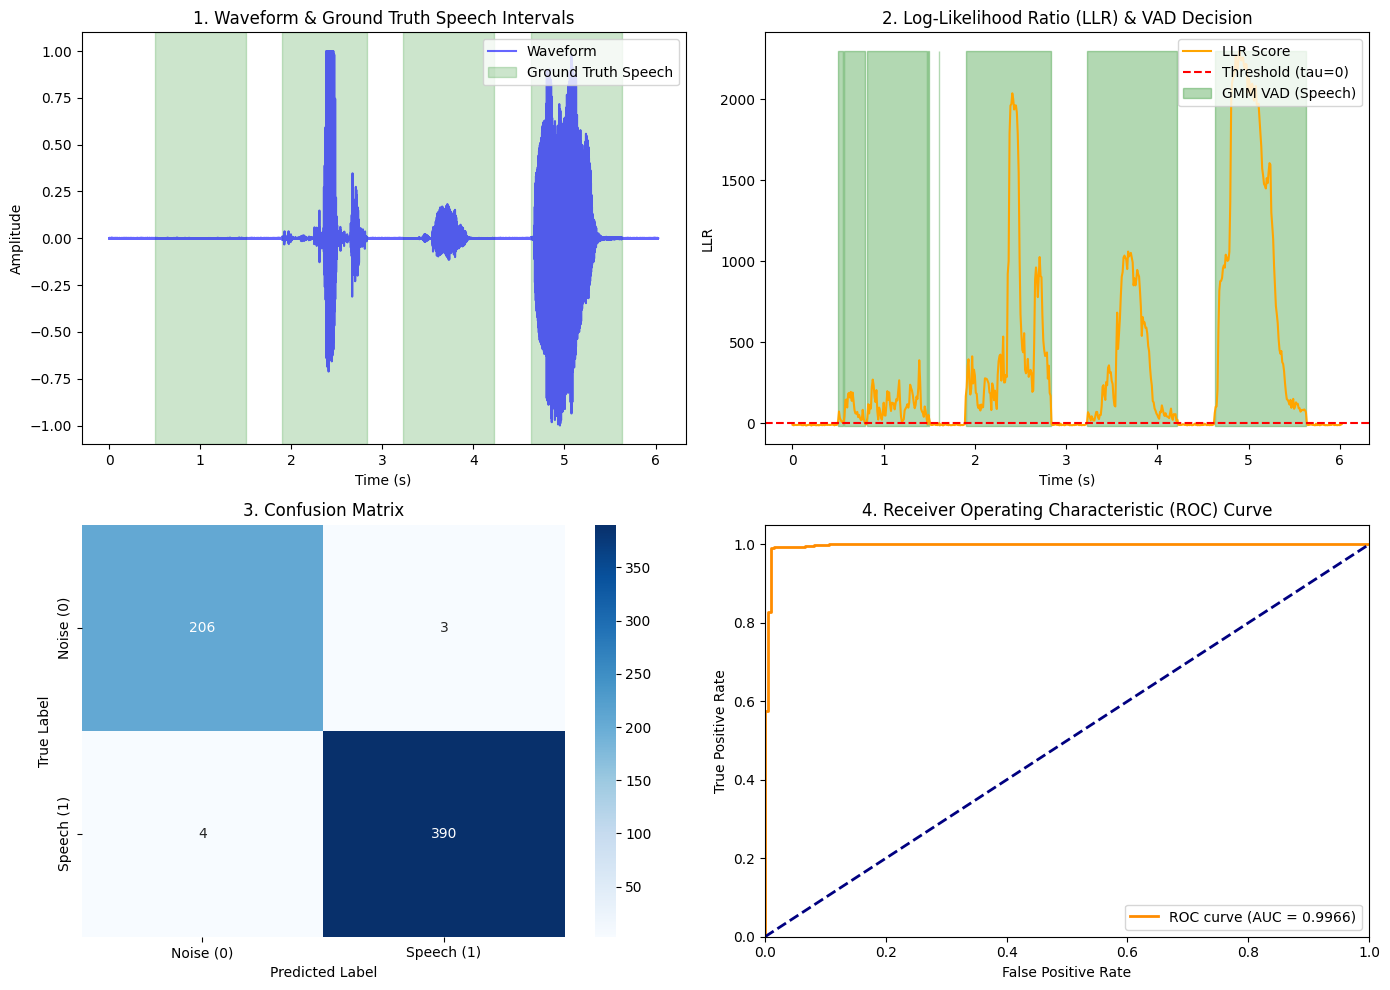

In [6]:
# TODO 5: Vẽ đồ thị tổng hợp kết quả Waveform VAD, Confusion Matrix và Đường cong ROC Curve
# Yêu cầu:
# 1. Subplot 1 (Waveform): Vẽ dạng sóng y(t) và tô màu nền phân đoạn Ground Truth (Green: Speech, Gray: Noise).
# 2. Subplot 2 (GMM VAD): Vẽ đè kết quả phân đoạn của GMM VAD và đường LLR Score.
# 3. Subplot 3 (Ma trận nhầm lẫn): Vẽ Heatmap Confusion Matrix 2x2 bằng sns.heatmap().
# 4. Subplot 4 (ROC Curve): Vẽ đường biểu diễn ROC Curve (FPR vs TPR) và hiển thị chỉ số AUC.

fig = plt.figure(figsize=(14, 10))

# Subplot 1 (Waveform)
ax1 = fig.add_subplot(2, 2, 1)
t_audio = np.linspace(0, len(y)/sr, len(y))
ax1.plot(t_audio, y, color='blue', alpha=0.6, label='Waveform')
for start_t, end_t in speech_intervals:
    ax1.axvspan(start_t, end_t, color='green', alpha=0.2, label='Ground Truth Speech' if start_t == speech_intervals[0][0] else "")
ax1.set_title("1. Waveform & Ground Truth Speech Intervals")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Amplitude")
ax1.legend(loc='upper right')

# Subplot 2 (GMM VAD)
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(frame_times, llr, color='orange', label='LLR Score')
ax2.axhline(0.0, color='red', linestyle='--', label='Threshold (tau=0)')
ax2.fill_between(frame_times, llr.min(), llr.max(), where=(y_pred == 1), color='green', alpha=0.3, label='GMM VAD (Speech)')
ax2.set_title("2. Log-Likelihood Ratio (LLR) & VAD Decision")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("LLR")
ax2.legend(loc='upper right')

# Subplot 3 (Confusion Matrix)
ax3 = fig.add_subplot(2, 2, 3)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Noise (0)', 'Speech (1)'], yticklabels=['Noise (0)', 'Speech (1)'], ax=ax3)
ax3.set_title("3. Confusion Matrix")
ax3.set_xlabel("Predicted Label")
ax3.set_ylabel("True Label")

# Subplot 4 (ROC Curve)
ax4 = fig.add_subplot(2, 2, 4)
ax4.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax4.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax4.set_xlim([0.0, 1.0])
ax4.set_ylim([0.0, 1.05])
ax4.set_xlabel('False Positive Rate')
ax4.set_ylabel('True Positive Rate')
ax4.set_title('4. Receiver Operating Characteristic (ROC) Curve')
ax4.legend(loc="lower right")

plt.tight_layout()
plt.show()


## 7. Câu hỏi thảo luận & Mở rộng

**Câu hỏi 1:** Trong lớp `sklearn.mixture.GaussianMixture`, tham số `n_components` ảnh hưởng thế nào đến khả năng biểu diễn phân phối âm thanh của lớp Nhiễu (`gmm_noise`) và lớp Giọng nói (`gmm_speech`)? Tại sao lớp Giọng nói thường cần số lượng component cao hơn ($K=3$) so với lớp Nhiễu nền ($K=2$)?

*Trả lời của sinh viên:*
- Tham số `n_components` ($K$) quyết định số lượng phân phối Gaussian thành phần trong mô hình hỗn hợp. $K$ càng lớn thì mô hình càng có khả năng khớp các phân phối dữ liệu đa mốt (multimodal) phức tạp.
- Nhiễu nền thường có đặc tính thống kê tương đối tĩnh (stationary) hoặc thay đổi chậm với phổ năng lượng tương đối ổn định, do đó chỉ cần $K=2$ component là đủ mô tả.
- Giọng nói con người có tính chất phi tĩnh (non-stationary), bao gồm nhiều dạng âm tiết đa dạng (nguyên âm, phụ âm vô thanh, phụ âm hữu thanh, âm bật) với các cấu hình phổ tần số rất khác nhau. Do đó, lớp Giọng nói cần số lượng component cao hơn ($K=3$ hoặc lớn hơn) để biểu diễn đầy đủ tính đa mốt của dữ liệu giọng nói.


**Câu hỏi 2:** Dựa trên đường cong ROC Curve và các chỉ số Precision/Recall thu được từ `sklearn.metrics`, làm thế nào để điều chỉnh ngưỡng $\tau$ của LLR nhằm tối ưu bài toán VAD cho hệ thống Nhận dạng Giọng nói (Speech Recognition - ASR) so với hệ thống Nén cuộc gọi VoIP?

*Trả lời của sinh viên:*
- **Đối với hệ thống Nhận dạng Giọng nói (ASR)**: Ưu tiên hàng đầu là không được làm mất hoặc cắt xén các phân đoạn giọng nói (tối ưu hóa **Recall** của lớp Speech, giảm tối đa False Negative). Do đó, nên hạ thấp ngưỡng $\tau < 0$ để hệ thống VAD sẵn sàng bắt giữ rộng hơn các đoạn nghi vấn có tiếng nói, tránh làm ngắt lời hoặc mất âm tiết đầu/cuối của câu lệnh ASR.
- **Đối với hệ thống Nén cuộc gọi VoIP**: Ưu tiên tối ưu băng thông và giảm lượng dữ liệu thừa gửi qua mạng khi người dùng giữ im lặng (tối ưu hóa **Precision** của lớp Speech, giảm tối đa False Positive ở các đoạn nhiễu). Do đó, nên nâng cao ngưỡng $\tau > 0$ để hệ thống chỉ kích hoạt truyền gói tin khi thực sự có tiếng nói với độ tin cậy cao.
